# Mini2P maze video tracking — memory-safe version

This notebook processes long videos without loading every frame into RAM. It uses three passes through the video: one pass to compute the mean frame, one pass to extract positions, and one optional pass to save an annotated video.

In [16]:
import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [2]:
# -----------------------------
# Set paths
# -----------------------------
base_path = Path('/Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522')
behavioral_path = base_path / 'behav'
imaging_path = base_path / 'funcimg'

print('Behavioral path:', behavioral_path)
print('Imaging path:', imaging_path)
print('Behavioral path exists:', behavioral_path.exists())
print('Imaging path exists:', imaging_path.exists())

Behavioral path: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav
Imaging path: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/funcimg
Behavioral path exists: True
Imaging path exists: True


In [3]:
# -----------------------------
# Find video file
# -----------------------------
video_extensions = ('.mp4', '.avi', '.mov', '.m4v')
video_files = sorted([p for p in behavioral_path.iterdir() if p.suffix.lower() in video_extensions])

if len(video_files) == 0:
    raise FileNotFoundError(f'No video file found in: {behavioral_path}')

# Use the first video found. Change this manually if needed.
video_file = video_files[0]
print(f'Using video file: {video_file}')

Using video file: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav/MY_71_R_2026-05-22-154652.mp4


In [4]:
# -----------------------------
# Inspect video metadata
# -----------------------------
def get_video_info(video_path):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f'Could not open video: {video_path}')

    info = {
        'n_frames': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        'fps': float(cap.get(cv2.CAP_PROP_FPS)),
        'width': int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        'height': int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
    }
    cap.release()
    info['duration_s'] = info['n_frames'] / info['fps'] if info['fps'] > 0 else np.nan
    info['duration_min'] = info['duration_s'] / 60 if info['fps'] > 0 else np.nan
    return info

video_info = get_video_info(video_file)
video_info

{'n_frames': 110311,
 'fps': 60.0,
 'width': 1280,
 'height': 1024,
 'duration_s': 1838.5166666666667,
 'duration_min': 30.641944444444444}

In [5]:
# -----------------------------
# User settings
# -----------------------------
# Process every nth frame. Use 1 for every frame. For a quick test, try 5 or 10 first.
FRAME_STEP = 1

# Maximum jump between consecutive frames before a point is treated as an outlier.
JUMP_THRESHOLD_PIXELS = 50

# Window used to fill outlier values by local median.
MEDIAN_FILL_WINDOW = 10

# Whether to save an annotated output video. This takes another pass through the video.
SAVE_ANNOTATED_VIDEO = True

# Output files
tracking_csv = behavioral_path / 'tracking_results_memory_safe.csv'
mean_frame_file = behavioral_path / 'mean_frame.npy'
annotated_video_file = behavioral_path / 'output_video_tracked.mp4'

In [6]:
# -----------------------------
# Pass 1: compute mean frame without loading full video
# -----------------------------
def compute_mean_frame(video_path, frame_step=1, grayscale=False):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f'Could not open video: {video_path}')

    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    mean_frame = None
    used_frames = 0

    for frame_idx in tqdm(range(n_frames), desc='Computing mean frame'):
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % frame_step != 0:
            continue

        if grayscale:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        frame_float = frame.astype(np.float64)
        if mean_frame is None:
            mean_frame = np.zeros_like(frame_float)

        # Online/incremental mean: avoids storing all frames.
        used_frames += 1
        mean_frame += (frame_float - mean_frame) / used_frames

    cap.release()

    if mean_frame is None:
        raise RuntimeError('No frames were read from the video.')

    return mean_frame.astype(np.uint8), used_frames

mean_frame, n_mean_frames = compute_mean_frame(video_file, frame_step=FRAME_STEP, grayscale=False)
np.save(mean_frame_file, mean_frame)

print(f'Mean frame computed from {n_mean_frames} frames')
print(f'Saved mean frame to: {mean_frame_file}')

Computing mean frame: 100%|██████████| 110311/110311 [22:44<00:00, 80.83it/s] 


Mean frame computed from 110311 frames
Saved mean frame to: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav/mean_frame.npy


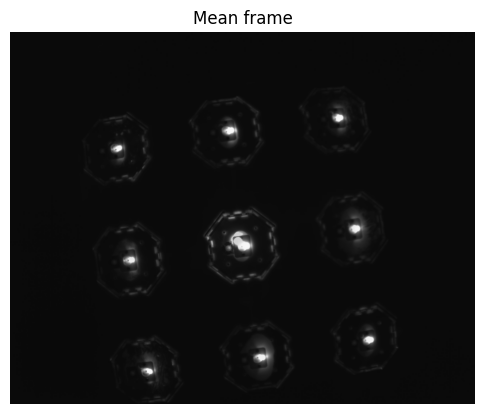

In [7]:
# Display mean frame
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(mean_frame, cv2.COLOR_BGR2RGB))
plt.title('Mean frame')
plt.axis('off')
plt.show()

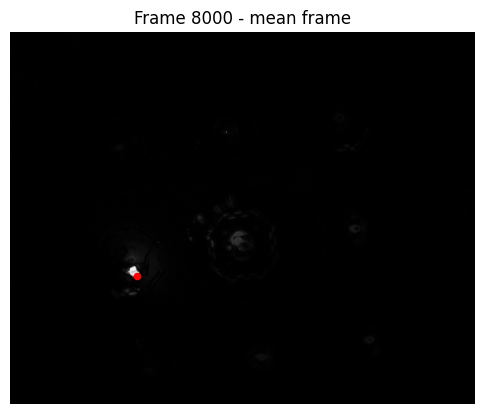

Max-difference position: 350 670


In [8]:
# -----------------------------
# Optional: inspect one example frame against the mean frame
# -----------------------------
example_frame_idx = min(8000, video_info['n_frames'] - 1)

cap = cv2.VideoCapture(str(video_file))
cap.set(cv2.CAP_PROP_POS_FRAMES, example_frame_idx)
ret, example_frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError(f'Could not read frame {example_frame_idx}')

diff_frame = cv2.absdiff(example_frame, mean_frame)
# Sum across color channels so each pixel has one difference value.
diff_gray = diff_frame.sum(axis=2)
y, x = np.unravel_index(np.argmax(diff_gray), diff_gray.shape)

plt.figure(figsize=(6, 6))
plt.imshow(diff_gray, cmap='gray')
plt.scatter([x], [y], color='red', s=20)
plt.title(f'Frame {example_frame_idx} - mean frame')
plt.axis('off')
plt.show()

print('Max-difference position:', x, y)

In [9]:
# -----------------------------
# Pass 2: track position frame-by-frame without storing video frames
# -----------------------------
def track_video_by_mean_difference(video_path, mean_frame, frame_step=1):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f'Could not open video: {video_path}')

    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))

    positions = []

    for frame_idx in tqdm(range(n_frames), desc='Tracking frames'):
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % frame_step != 0:
            continue

        diff_frame = cv2.absdiff(frame, mean_frame)
        diff_gray = diff_frame.sum(axis=2)
        y, x = np.unravel_index(np.argmax(diff_gray), diff_gray.shape)

        positions.append({
            'frame': frame_idx,
            'time_s': frame_idx / fps if fps > 0 else np.nan,
            'x_raw': float(x),
            'y_raw': float(y),
        })

    cap.release()
    return pd.DataFrame(positions)

tracking_df = track_video_by_mean_difference(video_file, mean_frame, frame_step=FRAME_STEP)
tracking_df.head()

Tracking frames: 100%|██████████| 110311/110311 [23:04<00:00, 79.68it/s] 


,frame,time_s,x_raw,y_raw
0,0,0.000000,683.0,920.0
1,1,0.016667,686.0,919.0
2,2,0.033333,684.0,919.0
3,3,0.050000,685.0,918.0
4,4,0.066667,684.0,919.0


In [10]:
# -----------------------------
# Outlier detection and correction
# -----------------------------
def correct_position_outliers(df, jump_threshold=50, median_window=10, max_iterations=20):
    out = df.copy()
    out['x'] = out['x_raw'].astype(float)
    out['y'] = out['y_raw'].astype(float)

    total_outliers = 0

    for iteration in range(max_iterations):
        dx = np.diff(out['x'].to_numpy())
        dy = np.diff(out['y'].to_numpy())
        jump = np.sqrt(dx**2 + dy**2)

        # +1 marks the frame after the jump as the bad point.
        outlier_idx = np.where(jump > jump_threshold)[0] + 1
        outlier_idx = outlier_idx[~np.isnan(out.loc[outlier_idx, 'x'].to_numpy())]

        if len(outlier_idx) == 0:
            print(f'No more outliers after {iteration} iteration(s).')
            break

        total_outliers += len(outlier_idx)
        out.loc[outlier_idx, ['x', 'y']] = np.nan

        # Fill NaNs using local median.
        for idx in outlier_idx:
            lo = max(0, idx - median_window)
            hi = min(len(out), idx + median_window + 1)
            out.loc[idx, 'x'] = np.nanmedian(out.loc[lo:hi, 'x'])
            out.loc[idx, 'y'] = np.nanmedian(out.loc[lo:hi, 'y'])

    out['is_outlier_corrected'] = (
        (out['x'] != out['x_raw']) | (out['y'] != out['y_raw'])
    )

    print(f'Total outlier corrections applied: {total_outliers}')
    return out

tracking_df = correct_position_outliers(
    tracking_df,
    jump_threshold=JUMP_THRESHOLD_PIXELS,
    median_window=MEDIAN_FILL_WINDOW,
)

tracking_df.to_csv(tracking_csv, index=False)
print(f'Saved tracking results to: {tracking_csv}')
tracking_df.head()

Total outlier corrections applied: 5257
Saved tracking results to: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav/tracking_results_memory_safe.csv


,frame,time_s,x_raw,y_raw,x,y,is_outlier_corrected
0,0,0.000000,683.0,920.0,683.0,920.0,False
1,1,0.016667,686.0,919.0,686.0,919.0,False
2,2,0.033333,684.0,919.0,684.0,919.0,False
3,3,0.050000,685.0,918.0,685.0,918.0,False
4,4,0.066667,684.0,919.0,684.0,919.0,False


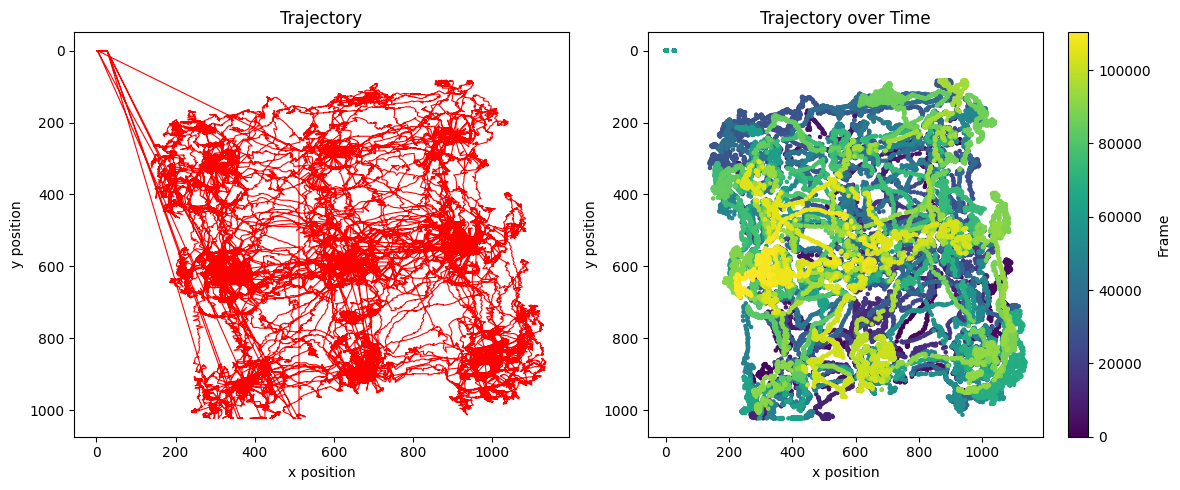

In [19]:
# -----------------------------
# Plot trajectory
# -----------------------------
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(tracking_df['x'], tracking_df['y'], color='red', linewidth=0.8)
plt.gca().invert_yaxis()
plt.xlabel('x position')
plt.ylabel('y position')
plt.title('Trajectory')

plt.subplot(1, 2, 2)
plt.scatter(
    tracking_df['x'],
    tracking_df['y'],
    c=tracking_df['frame'],
    cmap='viridis',
    s=5,
)
plt.gca().invert_yaxis()
plt.xlabel('x position')
plt.ylabel('y position')
plt.title('Trajectory over Time')
plt.colorbar(label='Frame')

plt.tight_layout()
plt.show()

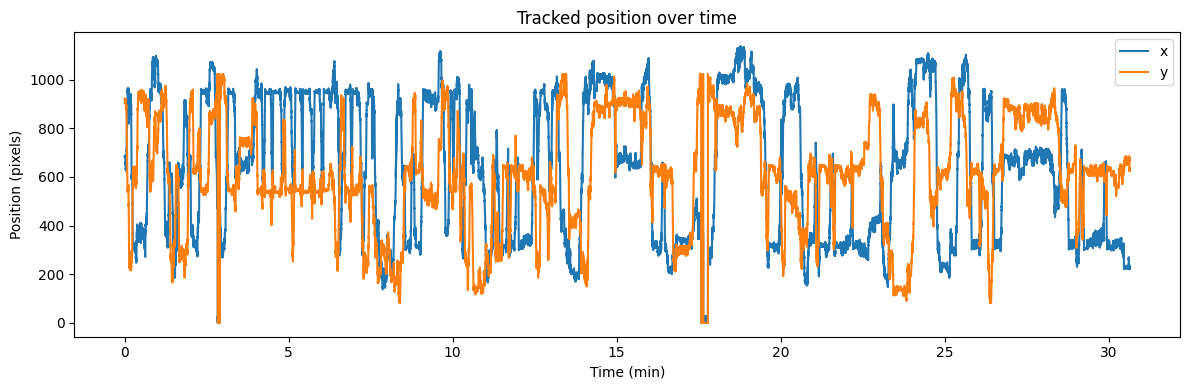

In [12]:
# -----------------------------
# Plot x/y over time
# -----------------------------
plt.figure(figsize=(12, 4))
plt.plot(tracking_df['time_s'] / 60, tracking_df['x'], label='x')
plt.plot(tracking_df['time_s'] / 60, tracking_df['y'], label='y')
plt.xlabel('Time (min)')
plt.ylabel('Position (pixels)')
plt.title('Tracked position over time')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# -----------------------------
# Pass 3: save annotated video without storing all frames
# -----------------------------
def save_annotated_video(video_path, tracking_df, output_path, frame_step=1):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f'Could not open video: {video_path}')

    fps = float(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # If frame_step > 1, output FPS is reduced so playback speed stays similar.
    output_fps = fps / frame_step if frame_step > 0 else fps

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(str(output_path), fourcc, output_fps, (width, height))

    pos_lookup = tracking_df.set_index('frame')[['x', 'y']].to_dict('index')

    for frame_idx in tqdm(range(n_frames), desc='Writing annotated video'):
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % frame_step != 0:
            continue

        pos = pos_lookup.get(frame_idx)
        if pos is not None and not np.isnan(pos['x']) and not np.isnan(pos['y']):
            cv2.circle(frame, (int(pos['x']), int(pos['y'])), 5, (0, 0, 255), -1)

        out.write(frame)

    cap.release()
    out.release()
    print(f'Saved annotated video to: {output_path}')

if SAVE_ANNOTATED_VIDEO:
    save_annotated_video(video_file, tracking_df, annotated_video_file, frame_step=FRAME_STEP)
else:
    print('Skipping annotated video because SAVE_ANNOTATED_VIDEO = False')

Writing annotated video: 100%|██████████| 110311/110311 [06:01<00:00, 305.50it/s]


Saved annotated video to: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav/output_video_tracked.mp4


In [14]:
# Final outputs
print('Done.')
print('Tracking CSV:', tracking_csv)
print('Mean frame:', mean_frame_file)
if SAVE_ANNOTATED_VIDEO:
    print('Annotated video:', annotated_video_file)

Done.
Tracking CSV: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav/tracking_results_memory_safe.csv
Mean frame: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav/mean_frame.npy
Annotated video: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-131_date-20260522/behav/output_video_tracked.mp4
